# From measured triples to probability state space

Setup is in [Tutorial.ipynb](Tutorial.ipynb). No external data or caches are required.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cirq
from pathlib import Path
import tempfile

from cirq_sic.measurements import Measurement, sic_povm, wh_measurement
from cirq_sic.workflow import (
    Experiment, ExperimentResult, tomography_experiment, entropy_experiment,
    wh_entropy_experiment, sky_ground_experiment, triple_product_experiment,
    compile_circuit,
)
from cirq_sic.analysis import stabilizer_renyi_entropy, born_rule_diagnostics
from cirq_sic.triples import triple_products, triple_product_state_space, sic_state_constraints

rng = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Cirq', cirq.__version__)

Cirq 1.3.0


In [2]:
qubit_sic = sic_povm(2)
magic = qubit_sic.states[:, 0]

## 4. Reconstruct probability state space from triple measurements

For SIC projectors $\Pi_i$, measure
$T_{ijk}=\mathrm{Tr}(\Pi_i\Pi_j\Pi_k)$ using a control qubit and a controlled
three-register cycle. Measuring control $X$ yields the real part; control $Y$
yields the imaginary part with a fixed orientation. Both components are tested
in the library, since a reversed cycle conjugates the answer.

Only sorted triples are scheduled by default. Cyclic permutations preserve a
triple and odd permutations conjugate it. Repeated-index imaginary parts vanish.
For $m$ states there are $2\binom{m+2}{3}$ circuits; select a subset in larger
experiments rather than materializing a full $d^6$ tensor.

In [3]:
triple_plan = triple_product_experiment(qubit_sic.states.T)
triple_report = triple_plan.analyze(triple_plan.simulate())
T = triple_report['tensor']
assert np.allclose(T, triple_products(qubit_sic.effects * 2), atol=1e-10)
print('Cycle-test circuits:', len(triple_plan.circuits))
print('An oriented triple:', T[0, 1, 2])
p_magic = qubit_sic.probabilities(magic)
constraints = sic_state_constraints(p_magic, T, 2)
print('Purity / cubic moment:', constraints['purity'], constraints['cubic'])
assert constraints['is_physical'] and constraints['is_pure']

Cycle-test circuits: 40
An oriented triple: -0.1924500897298752j
Purity / cubic moment: 1.0000000000000013 1.000000000000002


The measured tensor supplies a full positivity test, beyond just purity and
cubic moment bounds. Let $G_{jk}=\mathrm{Tr}(\Pi_j\Pi_k)$ and
$A_{i,j,k}=(d+1)T_{j,i,k}-G_{jk}$. A normalized probability vector is physical iff
$\sum_i p_i A_i\succeq0$, for exact SIC triple data. This reconstructs the state
space in probability coordinates without identifying a unique Hilbert-space
orientation. With noisy triples the resulting region is an estimated geometry,
not a certified SIC.

Here is a two-dimensional section through the uniform distribution, using only
the real triple tensor. For a qubit it is a circular section of the Bloch ball
expressed in SIC probability coordinates.

Section output fields: ['A_matrices', 'B', 'active_constraint', 'boundary_x', 'boundary_y', 'x_center']


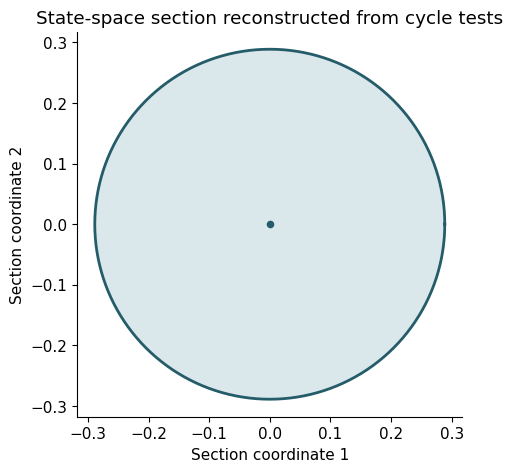

In [4]:
from cirq_sic.geometry import make_sum_zero_section, probability_spectrahedron_section_2D
A = triple_product_state_space(T, 2)
center = np.full(4, .25)
B = make_sum_zero_section([[1, -1, 0, 0], [0, 0, 1, -1]])
section = probability_spectrahedron_section_2D(A, center, B, num_angles=160)
print('Section output fields:', sorted(section))
boundary = section['boundary_y']
closed = np.vstack([boundary, boundary[0]])
fig, ax = plt.subplots(figsize=(5, 5))
ax.fill(closed[:, 0], closed[:, 1], color='#4c8f9b', alpha=.2)
ax.plot(closed[:, 0], closed[:, 1], color='#245c69', lw=2)
ax.scatter([0], [0], color='#245c69', s=20)
ax.set(xlabel='Section coordinate 1', ylabel='Section coordinate 2',
       title='State-space section reconstructed from cycle tests', aspect='equal')
plt.show()
assert np.all(section['boundary_x'] >= -1e-10)


## Sampling and partial characterization

A full tensor from noisy data defines an estimated region and can violate exact
SIC identities. Start with selected triples when circuit budget is limited;
the result intentionally omits a full tensor instead of filling missing entries
with zero.

In [5]:
partial = triple_product_experiment(qubit_sic.states.T, triplets=[(0, 1, 2)])
observed = partial.analyze(partial.run(repetitions=12000, seed=72))
print('Measured / exact:', observed['estimates'][0], T[0, 1, 2])
assert 'tensor' not in observed
assert abs(observed['estimates'][0] - T[0, 1, 2]) < .04

Measured / exact: (-0.0044999999999999485-0.21833333333333338j) -0.1924500897298752j
